# Heterogeneous Electron-Transfer Kinetics: Butler–Volmer Cyclic Voltammetry & Nicholson Analysis

This tutorial demonstrates how to configure **Butler–Volmer** heterogeneous electron-transfer kinetics in Soft Potato ([`softpotato.reactions`](../api/reactions.md)), simulate cyclic voltammetry (CV) across **reversible**, **quasi-reversible**, and **irreversible** regimes, and benchmark peak currents and peak-to-peak separations $\Delta E_p$ against **Randles–Ševčík**, **Matsuda–Ayabe**, and **Nicholson** theory ([`softpotato.analytical.voltammetry`](../api/analytical/voltammetry.md)).

### Learning Objectives
1. Configure `ButlerVolmer` and `TafelKinetics` interfacial charge-transfer models and inspect forward/backward rate constants $k_f(E)$, $k_b(E)$, and exchange current density $j_0$.
2. Couple Butler–Volmer interfacial flux boundary conditions into a stiff `ScipyIVPSolver(method="Radau")` cyclic voltammetry simulation using `CustomMechanism` and `GeometricExpandingMesh`.
3. Compare simulated cyclic voltammograms across reversible, quasi-reversible, and irreversible regimes.
4. Analyze peak potential separation $\Delta E_p$ vs. scan rate $v$, compare against Nicholson's $\Psi$ working curve, and extract $k^0$ from simulated CVs.


## 1. Theoretical Background

For a one-step heterogeneous electron-transfer reaction at a planar electrode ($x = 0$):

$$\text{Ox} + n e^- \underset{k_b(E)}{\overset{k_f(E)}{\rightleftharpoons}} \text{Red}$$

the **Butler–Volmer** rate constants as a function of electrode potential $E(t)$ are:

$$k_f(E) = k^0 \exp\!\left(-\frac{\alpha n F}{R T}(E - E^{0\prime})\right), \qquad k_b(E) = k^0 \exp\!\left(\frac{(1 - \alpha) n F}{R T}(E - E^{0\prime})\right)$$

At the electrode interface, Fick's first law balances diffusive transport with the net kinetic flux:

$$D_{\text{Ox}} \left.\frac{\partial c_{\text{Ox}}}{\partial x}\right|_{x=0} = -D_{\text{Red}} \left.\frac{\partial c_{\text{Red}}}{\partial x}\right|_{x=0} = k_f(E) c_{\text{Ox}}(0, t) - k_b(E) c_{\text{Red}}(0, t)$$

In cyclic voltammetry at scan rate $v$, kinetic reversibility is governed by the dimensionless **Matsuda–Ayabe** ($\Lambda$) and **Nicholson** ($\Psi$) parameters (for $D_{\text{Ox}} = D_{\text{Red}} = D$):

$$\Lambda = k^0 \sqrt{\frac{R T}{n F D v}}, \qquad \Psi = \frac{k^0}{\sqrt{\pi D n F v / (R T)}} = \frac{\Lambda}{\sqrt{\pi}}$$

- **Reversible** ($\Lambda \ge 15$): $\Delta E_p \approx 57.0 / n\,\text{mV}$ at $25\,^\circ\text{C}$, peak current obeys the reversible Randles–Ševčík equation.
- **Quasi-reversible** ($10^{-3} < \Lambda < 15$): $\Delta E_p$ increases smoothly with scan rate $v$ according to Nicholson's working curve.
- **Totally irreversible** ($\Lambda \le 10^{-3}$): reverse peak vanishes and forward peak current follows the irreversible Randles–Ševčík equation.


In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np

from softpotato.analytical.voltammetry import (
    matsuda_ayabe,
    nicholson_delta_ep,
    nicholson_rate_constant,
    randles_sevcik,
    randles_sevcik_irreversible,
)
from softpotato.constants import FARADAY, GAS_CONSTANT, STANDARD_TEMPERATURE
from softpotato.geometry import PlanarGeometry
from softpotato.grid import GeometricExpandingMesh
from softpotato.reactions import (
    ButlerVolmer,
    CustomMechanism,
    Species,
    TafelKinetics,
)
from softpotato.solver import DirichletBC, NeumannBC, ScipyIVPSolver

plt.rcParams.update(
    {
        "figure.dpi": 110,
        "axes.grid": True,
        "grid.alpha": 0.3,
        "font.size": 10,
    }
)

## 2. Inspecting `ButlerVolmer` and `TafelKinetics`

Let's instantiate a `ButlerVolmer` object and compare its steady kinetic current density $j(E)$ against the high-overpotential `TafelKinetics` approximation at fixed surface concentrations $c_{\text{Ox}} = c_{\text{Red}} = 1\,\text{mol/m}^3$.


Exchange current density j0 = 9.6485 A/m^2
At E = E0: kf = 1.00e-04 m/s, kb = 1.00e-04 m/s


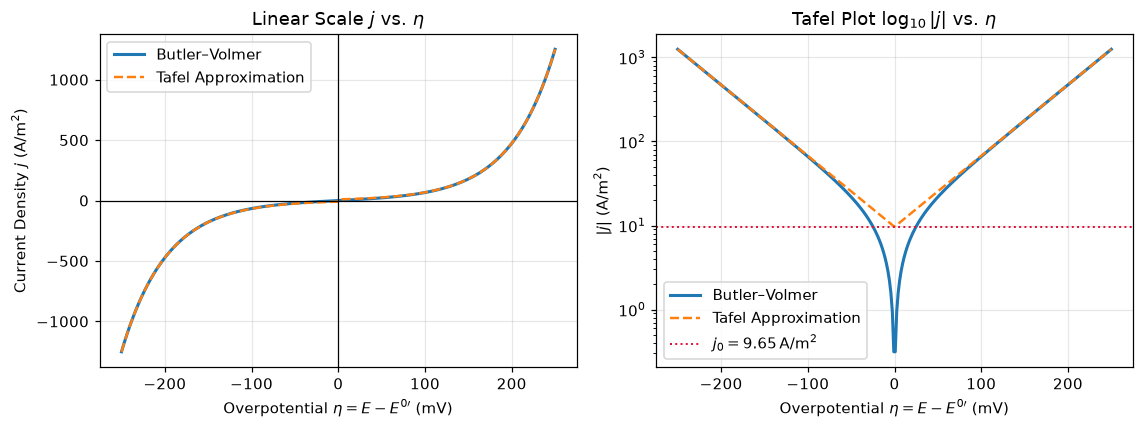

In [2]:
k0_demo = 1.0e-4  # m/s (1e-2 cm/s)
alpha = 0.5
E0 = 0.0

bv_demo = ButlerVolmer(k0=k0_demo, alpha=alpha, E0=E0, n=1, T=STANDARD_TEMPERATURE)
tafel_demo = TafelKinetics(
    k0=k0_demo, alpha=alpha, E0=E0, n=1, branch="auto", T=STANDARD_TEMPERATURE
)

E_grid = np.linspace(-0.25, 0.25, 300)
j_bv = bv_demo.current_density(E_grid, c_ox=1.0, c_red=1.0)
j_tafel = tafel_demo.current_density(E_grid, c_ox=1.0, c_red=1.0)
j0 = bv_demo.exchange_current_density(c_ox=1.0, c_red=1.0)

print(f"Exchange current density j0 = {j0:.4f} A/m^2")
kf0, kb0 = bv_demo.rate_constants(E0)
print(f"At E = E0: kf = {kf0:.2e} m/s, kb = {kb0:.2e} m/s")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.5, 4.0))
ax1.plot(E_grid * 1e3, j_bv, lw=2.0, label="Butler–Volmer")
ax1.plot(E_grid * 1e3, j_tafel, "--", lw=1.6, label="Tafel Approximation")
ax1.axhline(0.0, color="black", lw=0.8)
ax1.axvline(0.0, color="black", lw=0.8)
ax1.set_xlabel(r"Overpotential $\eta = E - E^{0\prime}$ (mV)")
ax1.set_ylabel(r"Current Density $j$ (A/m$^2$)")
ax1.set_title(r"Linear Scale $j$ vs. $\eta$")
ax1.legend()

ax2.semilogy(
    E_grid * 1e3, np.maximum(np.abs(j_bv), 1e-6), lw=2.0, label="Butler–Volmer"
)
ax2.semilogy(
    E_grid * 1e3,
    np.maximum(np.abs(j_tafel), 1e-6),
    "--",
    lw=1.6,
    label="Tafel Approximation",
)
ax2.axhline(
    j0, color="crimson", ls=":", lw=1.3, label=rf"$j_0 = {j0:.2f}\,\mathrm{{A/m}}^2$"
)
ax2.set_xlabel(r"Overpotential $\eta = E - E^{0\prime}$ (mV)")
ax2.set_ylabel(r"$|j|$ (A/m$^2$)")
ax2.set_title(r"Tafel Plot $\log_{10}|j|$ vs. $\eta$")
ax2.legend()
plt.tight_layout()
plt.show()

## 3. Butler–Volmer Cyclic Voltammetry Simulator

To enforce the coupled Robin boundary condition $D (\partial c_{\text{Ox}} / \partial x)|_{x=0} = k_f(E) c_{\text{Ox}}(0,t) - k_b(E) c_{\text{Red}}(0,t)$ with high accuracy and stiff stability across all $k^0$ regimes, we pair `ButlerVolmer` with `CustomMechanism` on a `GeometricExpandingMesh`:

- The interfacial half-cell finite-volume flux term injects $\mp (2 / h_0) J_{\text{BV}}$ at the surface node $x_0 = 0$ (with homogeneous zero-flux `NeumannBC(0.0)` for the diffusion stencil).
- Providing the exact analytical local Jacobian `local_jacobian_func` allows `ScipyIVPSolver(method="Radau")` to integrate seamlessly from fast reversible ($k^0 = 1\,\text{cm/s}$) down to sluggish irreversible ($k^0 = 10^{-5}\,\text{cm/s}$) kinetics.


In [3]:
def parabolic_peak(x: np.ndarray, y: np.ndarray, idx: int) -> tuple[float, float]:
    """Refine peak potential and peak current via 3-point parabolic interpolation."""
    if 0 < idx < len(x) - 1:
        x0, x1, x2 = float(x[idx - 1]), float(x[idx]), float(x[idx + 1])
        y0, y1, y2 = float(y[idx - 1]), float(y[idx]), float(y[idx + 1])
        denom = (x0 - x1) * (x0 - x2) * (x1 - x2)
        if abs(denom) > 0.0:
            a = (x2 * (y1 - y0) + x1 * (y0 - y2) + x0 * (y2 - y1)) / denom
            b = (
                (x2**2) * (y0 - y1) + (x1**2) * (y2 - y0) + (x0**2) * (y1 - y2)
            ) / denom
            c = (
                x1 * x2 * (x1 - x2) * y0
                + x2 * x0 * (x2 - x0) * y1
                + x0 * x1 * (x0 - x1) * y2
            ) / denom
            if abs(a) > 1e-30:
                xp = -b / (2.0 * a)
                if min(x0, x2) <= xp <= max(x0, x2):
                    return xp, a * xp**2 + b * xp + c
    return float(x[idx]), float(y[idx])


def simulate_bv_cv(
    k0_cm_s: float,
    v: float = 0.1,
    *,
    alpha: float = 0.5,
    D_cm2_s: float = 1e-5,
    c_bulk_mM: float = 1.0,
    area_cm2: float = 1.0,
    E0: float = 0.0,
    E_start: float = 0.45,
    E_switch: float = -0.65,
    n_points: int = 75,
    gamma: float = 1.10,
    n_eval: int = 601,
) -> dict:
    """Simulate a 1-electron Butler-Volmer CV in SI units and extract peak metrics."""
    D = D_cm2_s * 1e-4  # cm^2/s -> m^2/s
    c_bulk = c_bulk_mM  # 1 mM == 1 mol/m^3
    area = area_cm2 * 1e-4  # cm^2 -> m^2
    k0 = k0_cm_s * 1e-2  # cm/s -> m/s

    t_switch = (E_start - E_switch) / v
    t_end = 2.0 * t_switch

    def potential(t: float) -> float:
        return E_start - v * t if t <= t_switch else E_switch + v * (t - t_switch)

    domain_len = 6.0 * math.sqrt(D * t_end)
    mesh = GeometricExpandingMesh(0.0, domain_len, n_points=n_points, gamma=gamma)
    inv_half_cell = 2.0 / float(mesh.nodes[1] - mesh.nodes[0])

    bv = ButlerVolmer(k0=k0, alpha=alpha, E0=E0, n=1, T=STANDARD_TEMPERATURE)
    ox = Species("Ox", diffusivity=D, bulk_concentration=c_bulk, n_electrons=1)
    red = Species("Red", diffusivity=D, bulk_concentration=0.0, n_electrons=-1)

    def rates(c, x, t):
        kf, kb = bv.rate_constants(potential(t))
        j_bv = float(kf) * c["Ox"][0] - float(kb) * c["Red"][0]
        r_ox = np.zeros_like(c["Ox"])
        r_red = np.zeros_like(c["Red"])
        r_ox[0] = -inv_half_cell * j_bv
        r_red[0] = +inv_half_cell * j_bv
        return {"Ox": r_ox, "Red": r_red}

    def local_jac(c, x, t, species_names):
        kf, kb = bv.rate_constants(potential(t))
        jac = np.zeros((2, 2, len(c["Ox"])), dtype=float)
        io, ir = species_names.index("Ox"), species_names.index("Red")
        jac[io, io, 0] = -inv_half_cell * float(kf)
        jac[io, ir, 0] = +inv_half_cell * float(kb)
        jac[ir, io, 0] = +inv_half_cell * float(kf)
        jac[ir, ir, 0] = -inv_half_cell * float(kb)
        return jac

    mech = CustomMechanism(
        species=[ox, red],
        rates=rates,
        local_jacobian_func=local_jac,
        name=f"BV_CV_k0_{k0_cm_s:.1e}",
    )
    problem = mech.create_problem(
        mesh,
        boundary_conditions={
            "Ox": (NeumannBC(0.0), DirichletBC(c_bulk)),
            "Red": (NeumannBC(0.0), DirichletBC(0.0)),
        },
        geometry=PlanarGeometry(area=area),
    )

    t_eval = np.linspace(0.0, t_end, n_eval)
    result = ScipyIVPSolver(method="Radau", rtol=1e-7, atol=1e-10).solve(
        problem, t_span=(0.0, t_end), t_eval=t_eval
    )
    assert result.success, result.message

    E = np.array([potential(float(ti)) for ti in result.t])
    I = result.currents["Ox"]

    fwd = result.t <= t_switch
    rev = result.t >= t_switch
    Epc, Ipc = parabolic_peak(E[fwd], I[fwd], int(np.argmin(I[fwd])))
    Epa, Ipa = parabolic_peak(E[rev], I[rev], int(np.argmax(I[rev])))
    psi = k0 / math.sqrt(
        math.pi * D * FARADAY * v / (GAS_CONSTANT * STANDARD_TEMPERATURE)
    )

    return {
        "E": E,
        "I": I,
        "Epc": Epc,
        "Ipc": Ipc,
        "Epa": Epa,
        "Ipa": Ipa,
        "delta_ep_mV": (Epa - Epc) * 1e3,
        "psi": psi,
        "k0_m_s": k0,
        "D_m2_s": D,
        "area_m2": area,
        "c_bulk": c_bulk,
    }

## 4. Cyclic Voltammetry Across Reversible, Quasi-Reversible, and Irreversible Regimes

Let's simulate CVs at a fixed scan rate $v = 0.1\,\text{V/s}$ across four orders of magnitude in $k^0$:
- $k^0 = 1.0\,\text{cm/s}$ (**Reversible**)
- $k^0 = 10^{-2}\,\text{cm/s}$ (**Quasi-reversible, fast**)
- $k^0 = 10^{-3}\,\text{cm/s}$ (**Quasi-reversible, slow**)
- $k^0 = 5 \times 10^{-6}\,\text{cm/s}$ (**Totally irreversible**)


Analytical Randles-Sevcik |I_p|: reversible = 268.65 uA, irreversible = 211.03 uA

 k0 (cm/s) | Zone (Matsuda-Ayabe) | |Ipc| (uA) |  Epc (mV) |  Epa (mV) |  dEp (mV)
----------------------------------------------------------------------------------


   1.0e+00 |           reversible |     268.59 |     -28.7 |      28.9 |      57.6


   1.0e-02 |     quasi-reversible |     252.15 |     -43.3 |      41.8 |      85.1


   1.0e-03 |     quasi-reversible |     217.51 |    -117.7 |     109.9 |     227.6


   5.0e-06 |         irreversible |     211.14 |    -388.7 |     383.0 |       n/a


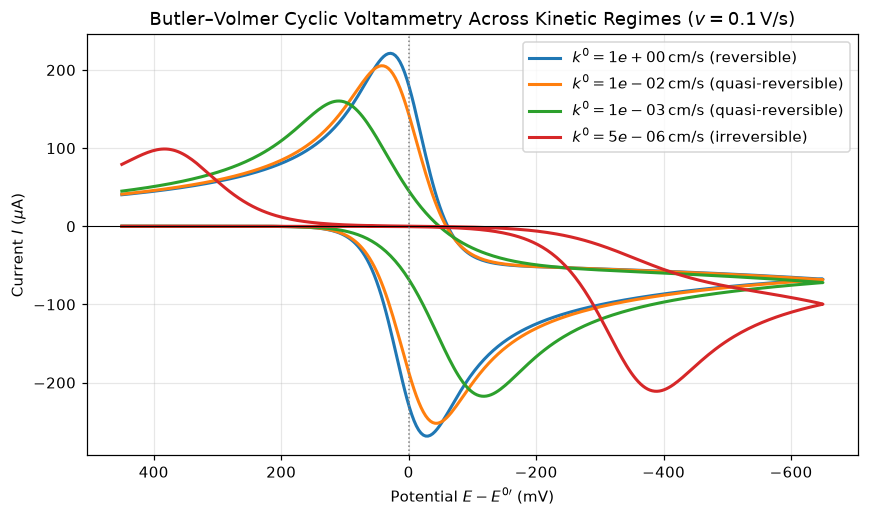

In [4]:
v_fixed = 0.1  # V/s
k0_cases = [
    (1.0, "Reversible"),
    (1e-2, "Quasi-reversible"),
    (1e-3, "Quasi-reversible"),
    (5e-6, "Irreversible"),
]

# Analytical Randles-Sevcik limits
D_si, A_si, c_si = 1e-9, 1e-4, 1.0
ip_rev = abs(randles_sevcik(v=v_fixed, c_bulk=c_si, D=D_si, area=A_si, n=1))
ip_irr = abs(
    randles_sevcik_irreversible(
        v=v_fixed, alpha=0.5, n_alpha=1, c_bulk=c_si, D=D_si, area=A_si, n=1
    )
)

print(
    f"Analytical Randles-Sevcik |I_p|: reversible = {ip_rev * 1e6:.2f} uA, irreversible = {ip_irr * 1e6:.2f} uA\n"
)
print(
    f"{'k0 (cm/s)':>10} | {'Zone (Matsuda-Ayabe)':>20} | {'|Ipc| (uA)':>10} | {'Epc (mV)':>9} | {'Epa (mV)':>9} | {'dEp (mV)':>9}"
)
print("-" * 82)

fig, ax = plt.subplots(figsize=(8.0, 4.8))
for k0_cm, _ in k0_cases:
    sim = simulate_bv_cv(k0_cm, v=v_fixed)
    ma = matsuda_ayabe(k0=sim["k0_m_s"], v=v_fixed, D=D_si, n=1)
    label = rf"$k^0 = {k0_cm:.0e}\,\mathrm{{cm/s}}$ ({ma.classification})"
    ax.plot(sim["E"] * 1e3, sim["I"] * 1e6, lw=2.0, label=label)
    dep_str = f"{sim['delta_ep_mV']:9.1f}" if k0_cm >= 1e-3 else "      n/a"
    print(
        f"{k0_cm:10.1e} | {ma.classification:>20} | {abs(sim['Ipc']) * 1e6:10.2f} | "
        f"{sim['Epc'] * 1e3:9.1f} | {sim['Epa'] * 1e3:9.1f} | {dep_str}"
    )

ax.axhline(0.0, color="black", lw=0.7)
ax.axvline(0.0, color="gray", ls=":", lw=1.0)
ax.set_xlabel(r"Potential $E - E^{0\prime}$ (mV)")
ax.set_ylabel(r"Current $I$ ($\mu$A)")
ax.set_title(
    rf"Butler–Volmer Cyclic Voltammetry Across Kinetic Regimes ($v = {v_fixed}\,\mathrm{{V/s}}$)"
)
ax.invert_xaxis()  # Traditional electrochemical convention (negative potentials to the right)
ax.legend()
plt.tight_layout()
plt.show()

## 5. Peak Separation $\Delta E_p$ vs. Scan Rate $v$ & Nicholson Extraction of $k^0$

In practice, electrochemists measure $k^0$ by varying the scan rate $v$ on a single redox system and tracking the growth of peak-to-peak separation $\Delta E_p = E_{pa} - E_{pc}$.

Let's fix $k^0 = 5 \times 10^{-3}\,\text{cm/s}$, sweep scan rates from $0.01$ to $3.0\,\text{V/s}$, compare the simulated $\Delta E_p$ directly against **Nicholson's working curve** (`nicholson_delta_ep`), and recover $k^0$ using `nicholson_rate_constant`.


True k0 = 5.00e-03 cm/s

 v (V/s) |      Psi |  dEp num (mV) |  dEp Nich (mV) |  Recovered k0 (cm/s)
--------------------------------------------------------------------------


    0.01 |    1.430 |         75.31 |          76.69 |            5.491e-03


    0.03 |    0.826 |         87.49 |          87.40 |            4.982e-03


    0.10 |    0.452 |        109.31 |         106.72 |            4.702e-03


    0.30 |    0.261 |        139.57 |         135.62 |            4.716e-03


    1.00 |    0.143 |        185.20 |         187.73 |            5.117e-03


    3.00 |    0.083 |        235.62 |         265.71 |            6.001e-03

Mean recovered k0 = 5.168e-03 cm/s (relative error: 3.36%)


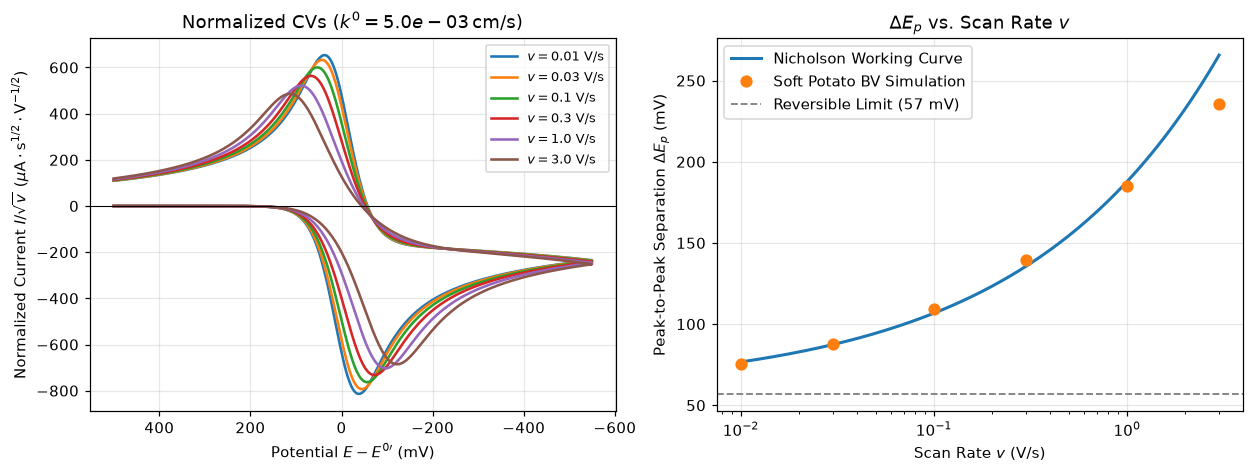

In [5]:
k0_true_cm = 5.0e-3  # cm/s (5e-5 m/s)
scan_rates = [0.01, 0.03, 0.1, 0.3, 1.0, 3.0]

sims_v = []
delta_ep_num = []
delta_ep_nich = []
k0_recovered = []

print(f"True k0 = {k0_true_cm:.2e} cm/s\n")
print(
    f"{'v (V/s)':>8} | {'Psi':>8} | {'dEp num (mV)':>13} | {'dEp Nich (mV)':>14} | {'Recovered k0 (cm/s)':>20}"
)
print("-" * 74)

for v in scan_rates:
    sim = simulate_bv_cv(k0_true_cm, v=v, E_start=0.50, E_switch=-0.55)
    dep_n = sim["delta_ep_mV"]
    dep_th = float(nicholson_delta_ep(sim["psi"], n=1)) * 1e3
    k0_est_cm = float(nicholson_rate_constant(dep_n * 1e-3, v=v, D=D_si, n=1)) * 1e2

    sims_v.append(sim)
    delta_ep_num.append(dep_n)
    delta_ep_nich.append(dep_th)
    k0_recovered.append(k0_est_cm)
    print(
        f"{v:8.2f} | {sim['psi']:8.3f} | {dep_n:13.2f} | {dep_th:14.2f} | {k0_est_cm:20.3e}"
    )

mean_k0 = float(np.mean(k0_recovered))
print(
    f"\nMean recovered k0 = {mean_k0:.3e} cm/s (relative error: {abs(mean_k0 - k0_true_cm) / k0_true_cm * 100:.2f}%)"
)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 4.4))

# Left: scan-rate normalized CVs (I / sqrt(v))
for v, sim in zip(scan_rates, sims_v):
    ax1.plot(
        sim["E"] * 1e3, (sim["I"] / math.sqrt(v)) * 1e6, lw=1.7, label=f"$v = {v}$ V/s"
    )
ax1.axhline(0.0, color="black", lw=0.7)
ax1.set_xlabel(r"Potential $E - E^{0\prime}$ (mV)")
ax1.set_ylabel(
    r"Normalized Current $I / \sqrt{v}$ ($\mu\mathrm{A}\cdot\mathrm{s}^{1/2}\cdot\mathrm{V}^{-1/2}$)"
)
ax1.set_title(rf"Normalized CVs ($k^0 = {k0_true_cm:.1e}\,\mathrm{{cm/s}}$)")
ax1.invert_xaxis()
ax1.legend(fontsize=8.5)

# Right: Delta Ep vs scan rate (log scale) compared to Nicholson theory
v_smooth = np.geomspace(min(scan_rates), max(scan_rates), 150)
psi_smooth = (k0_true_cm * 1e-2) / np.sqrt(
    math.pi * D_si * FARADAY * v_smooth / (GAS_CONSTANT * STANDARD_TEMPERATURE)
)
dep_smooth = nicholson_delta_ep(psi_smooth, n=1) * 1e3

ax2.semilogx(v_smooth, dep_smooth, "-", lw=2.0, label="Nicholson Working Curve")
ax2.semilogx(scan_rates, delta_ep_num, "o", ms=7, label="Soft Potato BV Simulation")
ax2.axhline(57.0, color="gray", ls="--", lw=1.2, label="Reversible Limit (57 mV)")
ax2.set_xlabel("Scan Rate $v$ (V/s)")
ax2.set_ylabel(r"Peak-to-Peak Separation $\Delta E_p$ (mV)")
ax2.set_title(r"$\Delta E_p$ vs. Scan Rate $v$")
ax2.legend()

plt.tight_layout()
plt.show()

## Summary

- `ButlerVolmer` and `TafelKinetics` provide vectorized interfacial rate constants, exchange current densities, and current–overpotential relations under consistent IUPAC conventions.
- Coupling `ButlerVolmer` with `CustomMechanism`, an analytical local Jacobian, and `GeometricExpandingMesh` reproduces reversible, quasi-reversible, and irreversible cyclic voltammograms accurately with `ScipyIVPSolver(method="Radau")`.
- Simulated peak separations $\Delta E_p(v)$ closely track Nicholson's theoretical working curve, allowing quantitative recovery of $k^0$ via `nicholson_rate_constant`.
